
# Projeto Final — Machine Learning e API com FastAPI

## 1. Introdução

Este projeto tem como objetivo desenvolver uma solução de Machine Learning integrada a uma API REST, utilizando Python. O trabalho contempla a preparação dos dados, o treinamento e a avaliação de um modelo preditivo, a disponibilização das previsões por meio de uma API e a realização de testes automatizados.

O desenvolvimento será realizado no Google Colab, e os arquivos do projeto serão organizados para posterior versionamento e documentação no GitHub.

## 2. Objetivo do projeto

Desenvolver um modelo de classificação capaz de prever a espécie de uma flor a partir de suas características físicas e disponibilizar essa previsão por meio de uma API construída com FastAPI.

## 3. Tecnologias utilizadas

- Python: linguagem de programação.
- Pandas: manipulação e análise de dados.
- Scikit-learn: preparação dos dados, treinamento e avaliação do modelo.
- Joblib: serialização do modelo treinado.
- FastAPI: desenvolvimento da API REST.
- Pydantic: validação dos dados de entrada e saída.
- Uvicorn: execução do servidor da API.
- Pytest e TestClient: testes automatizados.
- Git e GitHub: versionamento e compartilhamento do projeto.
- Google Colab: ambiente de desenvolvimento.

## 4. Organização do desenvolvimento

O projeto será desenvolvido em etapas: configuração do ambiente, exploração dos dados, preparação das amostras, treinamento e avaliação do modelo, serialização, construção da API, testes e documentação.



## 5. Configuração do ambiente

Nesta etapa, foram instaladas as bibliotecas necessárias para o desenvolvimento da solução. Cada biblioteca possui uma função específica no projeto, desde o processamento dos dados até a criação e os testes da API.

A instalação no Google Colab permite utilizar essas ferramentas sem configurar manualmente um ambiente Python na máquina local.


In [1]:
# ============================================================
# PROJETO FINAL — MACHINE LEARNING + API FASTAPI
# Etapa 1: Configurar o ambiente
# ============================================================

import sys
import os
from pathlib import Path

print("Python:", sys.version)
print("Diretório de trabalho:", os.getcwd())
print("Ambiente configurado para iniciar o projeto!")


Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Diretório de trabalho: /content
Ambiente configurado para iniciar o projeto!



## 6. Estrutura de diretórios

A organização do projeto em diretórios facilita a manutenção, a reutilização e os testes do código.

- `models/`: armazenamento do modelo treinado.
- `reports/`: métricas e resultados da avaliação.
- `src/`: código-fonte da aplicação.
- `src/routers/`: módulos responsáveis pelos endpoints da API.
- `tests/`: testes automatizados.
- `__init__.py`: arquivos que ajudam a organizar os módulos Python como pacotes importáveis.


In [2]:

# ============================================================
# # Etapa 2: criação da estrutura de pastas
# ============================================================

from pathlib import Path

# Pasta principal do projeto
BASE_DIR = Path("/content/projeto-ml-api")

# Pastas que serão utilizadas
pastas = [
    "models",
    "reports",
    "src",
    "src/routers",
    "tests"
]

# Criar as pastas
for pasta in pastas:
    (BASE_DIR / pasta).mkdir(parents=True, exist_ok=True)

# Criar arquivos iniciais para identificar os pacotes Python
(BASE_DIR / "src" / "__init__.py").touch()
(BASE_DIR / "src" / "routers" / "__init__.py").touch()

print("Estrutura do projeto criada com sucesso!")
print()

# Exibir a estrutura criada
for item in sorted(BASE_DIR.rglob("*")):
    if item.is_dir():
        print(f"[PASTA]  {item.relative_to(BASE_DIR)}")
    else:
        print(f"[ARQUIVO] {item.relative_to(BASE_DIR)}")


Estrutura do projeto criada com sucesso!

[PASTA]  .pytest_cache
[ARQUIVO] .pytest_cache/.gitignore
[ARQUIVO] .pytest_cache/CACHEDIR.TAG
[ARQUIVO] .pytest_cache/README.md
[PASTA]  .pytest_cache/v
[PASTA]  .pytest_cache/v/cache
[ARQUIVO] .pytest_cache/v/cache/nodeids
[ARQUIVO] README.md
[PASTA]  models
[ARQUIVO] models/model.joblib
[PASTA]  reports
[ARQUIVO] reports/metrics.json
[ARQUIVO] requirements.txt
[PASTA]  src
[ARQUIVO] src/__init__.py
[PASTA]  src/__pycache__
[ARQUIVO] src/__pycache__/__init__.cpython-313.pyc
[ARQUIVO] src/__pycache__/main.cpython-313.pyc
[ARQUIVO] src/__pycache__/schemas.cpython-313.pyc
[ARQUIVO] src/__pycache__/services.cpython-313.pyc
[ARQUIVO] src/main.py
[PASTA]  src/routers
[ARQUIVO] src/routers/__init__.py
[PASTA]  src/routers/__pycache__
[ARQUIVO] src/routers/__pycache__/__init__.cpython-313.pyc
[ARQUIVO] src/routers/__pycache__/health.cpython-313.pyc
[ARQUIVO] src/routers/__pycache__/predict.cpython-313.pyc
[ARQUIVO] src/routers/health.py
[ARQUIVO] src


## 7. Carregamento e exploração dos dados

Para este projeto, será utilizada a base Iris, disponibilizada pelo Scikit-learn. Ela contém 150 observações, quatro variáveis numéricas de entrada e três classes correspondentes a espécies de flores.

As variáveis de entrada representam o comprimento e a largura das sépalas e das pétalas. A variável-alvo identifica a espécie que o modelo deverá prever.

Nesta etapa, os dados são carregados e separados em `X`, que contém as variáveis preditoras, e `y`, que contém as classes. A exploração inicial permite verificar as dimensões da base, os nomes das variáveis e a distribuição das classes antes do treinamento.


In [3]:

# ============================================================
# ETAPA 3.1 — INSTALAÇÃO DAS BIBLIOTECAS
# ============================================================

%pip install -q scikit-learn pandas matplotlib seaborn joblib fastapi "uvicorn[standard]" httpx


In [4]:

# ============================================================
# ETAPA 3.2 — CARREGAMENTO E EXPLORAÇÃO INICIAL DOS DADOS
# ============================================================

import pandas as pd
from sklearn.datasets import load_iris

# Carregar a base Iris
iris = load_iris(as_frame=True)

# Separar variáveis de entrada (X) e variável-alvo (y)
X = iris.data.copy()
y = iris.target.copy()

# Nomes das espécies
nomes_classes = iris.target_names

print("Base de dados carregada com sucesso!")
print(f"\nQuantidade de registros: {X.shape[0]}")
print(f"Quantidade de variáveis de entrada: {X.shape[1]}")
print(f"Quantidade de classes: {len(nomes_classes)}")

print("\nVariáveis de entrada:")
print(X.columns.tolist())

print("\nClasses possíveis:")
for classe in nomes_classes:
    print("-", classe)

print("\nPrimeiras linhas da base:")
display(X.head())

print("\nDistribuição das classes:")
print(y.value_counts().sort_index())


Base de dados carregada com sucesso!

Quantidade de registros: 150
Quantidade de variáveis de entrada: 4
Quantidade de classes: 3

Variáveis de entrada:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Classes possíveis:
- setosa
- versicolor
- virginica

Primeiras linhas da base:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Distribuição das classes:
target
0    50
1    50
2    50
Name: count, dtype: int64



## 8. Separação dos dados em treino, validação e teste

Antes de treinar o modelo, os dados serão divididos em três conjuntos com finalidades distintas:

- **Treino (70%):** utilizado para que o algoritmo aprenda os padrões existentes nos dados.
- **Validação (15%):** utilizado durante o desenvolvimento para comparar alternativas e ajustar o modelo.
- **Teste (15%):** reservado para a avaliação final, após as decisões de desenvolvimento.

A divisão será estratificada, utilizando a variável-alvo como referência. Dessa forma, procuramos preservar a proporção das três espécies em cada conjunto.

Será utilizada uma semente aleatória fixa (`random_state=42`) para tornar a divisão reproduzível. Isso significa que, ao executar novamente o código nas mesmas condições, obteremos a mesma separação dos dados.


In [5]:

# ============================================================
# ETAPA 4 — SEPARAÇÃO DOS DADOS
# ============================================================

from sklearn.model_selection import train_test_split

# Primeira divisão:
# 70% para treino e 30% para validação + teste
X_treino, X_temp, y_treino, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Segunda divisão:
# dividir os 30% restantes igualmente
# 15% para validação e 15% para teste do total
X_validacao, X_teste, y_validacao, y_teste = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Conferir as dimensões dos conjuntos
print("Quantidade de registros por conjunto:")
print(f"Treino:     {len(X_treino)} registros")
print(f"Validação:  {len(X_validacao)} registros")
print(f"Teste:      {len(X_teste)} registros")

print("\nProporção de cada conjunto:")
print(f"Treino:     {len(X_treino) / len(X):.0%}")
print(f"Validação:  {len(X_validacao) / len(X):.0%}")
print(f"Teste:      {len(X_teste) / len(X):.0%}")


Quantidade de registros por conjunto:
Treino:     105 registros
Validação:  22 registros
Teste:      23 registros

Proporção de cada conjunto:
Treino:     70%
Validação:  15%
Teste:      15%



### Interpretação da divisão dos dados

A base original possui 150 observações. A separação foi realizada em duas etapas para obter aproximadamente 70% dos dados para treino e 15% para cada um dos conjuntos de validação e teste.

A estratificação ajuda a manter a representação das três espécies nos conjuntos. A semente fixa permite reproduzir a divisão durante o desenvolvimento.

O conjunto de teste será preservado para a avaliação final, evitando utilizá-lo para escolher ou ajustar o modelo.



## 9. Construção do pipeline e treinamento do modelo

Nesta etapa será desenvolvido um modelo de classificação supervisionada para prever a espécie de uma flor a partir de quatro características numéricas.

Será utilizado um pipeline do Scikit-learn, que reúne as etapas de preparação dos dados e o algoritmo de classificação em um único objeto.

O pipeline será composto por:

1. **Imputação de valores ausentes:** utilização da mediana de cada variável para preencher eventuais valores ausentes.
2. **Padronização:** transformação das variáveis numéricas para escalas comparáveis, utilizando a média e o desvio-padrão calculados nos dados de treino.
3. **Classificador:** utilização do algoritmo Regressão Logística, que estima a classe mais provável a partir das características de entrada.

A Regressão Logística foi escolhida como modelo inicial por ser um algoritmo conhecido, relativamente simples e adequado para estabelecer uma referência de desempenho em problemas de classificação.

O pipeline será ajustado exclusivamente com os dados de treino. Os dados de validação e teste não participarão desse ajuste.


In [6]:
# ============================================================
# ETAPA 5 — CONSTRUÇÃO E TREINAMENTO DO MODELO
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Criar o pipeline de Machine Learning
modelo = Pipeline(steps=[
    (
        "imputacao",
        SimpleImputer(strategy="median")
    ),
    (
        "padronizacao",
        StandardScaler()
    ),
    (
        "classificador",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

# Treinar o pipeline somente com os dados de treino
modelo.fit(X_treino, y_treino)

print("Modelo treinado com sucesso!")
print("\nEtapas do pipeline:")

for nome, etapa in modelo.steps:
    print(f"- {nome}: {etapa.__class__.__name__}")


Modelo treinado com sucesso!

Etapas do pipeline:
- imputacao: SimpleImputer
- padronizacao: StandardScaler
- classificador: LogisticRegression


In [7]:

# ============================================================
# ETAPA 5.1 — PRIMEIRAS PREVISÕES
# ============================================================

# Prever as espécies para os dados de validação
previsoes_validacao = modelo.predict(X_validacao)

# Mostrar algumas previsões e os valores reais
resultado_previsoes = X_validacao.head(10).copy()

resultado_previsoes["Classe real"] = [
    nomes_classes[int(classe)]
    for classe in y_validacao.iloc[:10]
]

resultado_previsoes["Classe prevista"] = [
    nomes_classes[int(classe)]
    for classe in previsoes_validacao[:10]
]

display(resultado_previsoes)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Classe real,Classe prevista
77,6.7,3.0,5.0,1.7,versicolor,virginica
111,6.4,2.7,5.3,1.9,virginica,virginica
69,5.6,2.5,3.9,1.1,versicolor,versicolor
133,6.3,2.8,5.1,1.5,virginica,versicolor
141,6.9,3.1,5.1,2.3,virginica,virginica
84,5.4,3.0,4.5,1.5,versicolor,versicolor
20,5.4,3.4,1.7,0.2,setosa,setosa
22,4.6,3.6,1.0,0.2,setosa,setosa
23,5.1,3.3,1.7,0.5,setosa,setosa
43,5.0,3.5,1.6,0.6,setosa,setosa



### Avaliação preliminar do modelo

Após o treinamento, o modelo será avaliado utilizando o conjunto de validação. Esses registros não foram utilizados para ajustar os parâmetros do pipeline.

Serão calculadas as seguintes métricas:

- **Acurácia (accuracy):** proporção de previsões corretas em relação ao total de previsões.
- **Precisão (precision):** proporção de previsões positivas de uma classe que realmente pertencem a essa classe.
- **Recall:** proporção de registros de uma classe que foram identificados corretamente.
- **F1-score:** média harmônica entre precisão e recall.

Como o problema possui três classes, será utilizada a média macro para precisão, recall e F1-score. Essa abordagem calcula a métrica de cada classe e atribui o mesmo peso às três espécies.


In [8]:

# ============================================================
# ETAPA 5.2 — MÉTRICAS DE VALIDAÇÃO
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calcular as métricas de validação
metricas_validacao = {
    "Acurácia": accuracy_score(
        y_validacao, previsoes_validacao
    ),
    "Precisão macro": precision_score(
        y_validacao, previsoes_validacao,
        average="macro", zero_division=0
    ),
    "Recall macro": recall_score(
        y_validacao, previsoes_validacao,
        average="macro", zero_division=0
    ),
    "F1-score macro": f1_score(
        y_validacao, previsoes_validacao,
        average="macro", zero_division=0
    )
}

print("MÉTRICAS DE VALIDAÇÃO")
print("=" * 35)

for metrica, valor in metricas_validacao.items():
    print(f"{metrica}: {valor:.4f}")

print("\nRelatório por espécie:")
print(
    classification_report(
        y_validacao,
        previsoes_validacao,
        labels=[0, 1, 2],
        target_names=list(nomes_classes),
        zero_division=0
    )
)


MÉTRICAS DE VALIDAÇÃO
Acurácia: 0.8636
Precisão macro: 0.8611
Recall macro: 0.8571
F1-score macro: 0.8564

Relatório por espécie:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         8
  versicolor       0.75      0.86      0.80         7
   virginica       0.83      0.71      0.77         7

    accuracy                           0.86        22
   macro avg       0.86      0.86      0.86        22
weighted avg       0.87      0.86      0.86        22




### Interpretação dos resultados de validação

O modelo foi treinado utilizando o conjunto de treino e avaliado no conjunto de validação.

A acurácia obtida foi de **0.8636**, enquanto o F1-score macro foi de **0.8564**.

Esses resultados representam o desempenho preliminar do classificador. A análise das métricas por espécie permite identificar se o modelo apresenta diferenças na capacidade de reconhecer cada classe.

O conjunto de validação poderá apoiar decisões durante o desenvolvimento. O conjunto de teste permanecerá reservado para a avaliação final, após a conclusão das escolhas do modelo.



### 9.1 Interpretação dos resultados de validação

O modelo de Regressão Logística apresentou acurácia de 86,36% no conjunto de validação, equivalente a 19 previsões corretas entre 22 registros. O F1-score macro foi de aproximadamente 0,8564, indicando um desempenho geral razoavelmente equilibrado entre as três classes.

A espécie *setosa* apresentou precisão, recall e F1-score de 1,00, demonstrando que todos os seus exemplares foram classificados corretamente nesse conjunto.

Para *versicolor*, o F1-score foi de 0,80, enquanto para *virginica* foi de 0,77. O recall de 0,71 para *virginica* indica que parte dos exemplares dessa espécie não foi identificada corretamente.

Os resultados indicam que o modelo constitui uma primeira referência de desempenho, mas ainda apresenta erros na distinção entre algumas classes. Como o conjunto de validação possui apenas 22 registros, as métricas devem ser interpretadas considerando o tamanho reduzido da amostra.

A avaliação final será realizada posteriormente com o conjunto de teste, que não foi utilizado no treinamento.



## 10. Avaliação final do modelo

Após o treinamento e a análise preliminar com o conjunto de validação, será realizada a avaliação final utilizando o conjunto de teste.

O conjunto de teste contém observações que não participaram do ajuste do pipeline. Ele permite estimar o desempenho do modelo em dados não utilizados durante o treinamento.

Serão calculadas a acurácia, a precisão macro, o recall macro e o F1-score macro. Também será gerada uma matriz de confusão para identificar quais espécies foram classificadas corretamente e quais foram confundidas pelo modelo.

Esses resultados serão registrados em um arquivo JSON para documentar a avaliação e facilitar a rastreabilidade do projeto.


In [9]:

# ============================================================
# ETAPA 6.1 — AVALIAÇÃO FINAL NO CONJUNTO DE TESTE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Gerar previsões para os dados de teste
previsoes_teste = modelo.predict(X_teste)

# Calcular as métricas finais
metricas_teste = {
    "accuracy": float(
        accuracy_score(y_teste, previsoes_teste)
    ),
    "precision_macro": float(
        precision_score(
            y_teste,
            previsoes_teste,
            average="macro",
            zero_division=0
        )
    ),
    "recall_macro": float(
        recall_score(
            y_teste,
            previsoes_teste,
            average="macro",
            zero_division=0
        )
    ),
    "f1_macro": float(
        f1_score(
            y_teste,
            previsoes_teste,
            average="macro",
            zero_division=0
        )
    )
}

print("RESULTADOS DA AVALIAÇÃO FINAL")
print("=" * 40)

for metrica, valor in metricas_teste.items():
    print(f"{metrica}: {valor:.4f}")

print("\nRelatório por espécie:")
print(
    classification_report(
        y_teste,
        previsoes_teste,
        labels=[0, 1, 2],
        target_names=list(nomes_classes),
        zero_division=0
    )
)


RESULTADOS DA AVALIAÇÃO FINAL
accuracy: 0.9565
precision_macro: 0.9630
recall_macro: 0.9583
f1_macro: 0.9582

Relatório por espécie:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         7
  versicolor       0.89      1.00      0.94         8
   virginica       1.00      0.88      0.93         8

    accuracy                           0.96        23
   macro avg       0.96      0.96      0.96        23
weighted avg       0.96      0.96      0.96        23



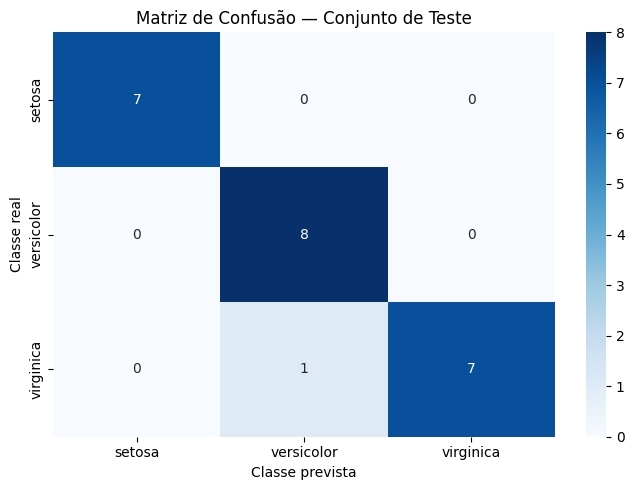

In [10]:

# ============================================================
# ETAPA 6.2 — MATRIZ DE CONFUSÃO
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Manter a ordem das classes
ordem_classes = [0, 1, 2]

matriz = confusion_matrix(
    y_teste,
    previsoes_teste,
    labels=ordem_classes
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nomes_classes,
    yticklabels=nomes_classes
)

plt.title("Matriz de Confusão — Conjunto de Teste")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()


In [11]:

# ============================================================
# ETAPA 6.3 — SALVAMENTO DOS ARTEFATOS
# ============================================================

import json
import joblib

# Garantir que as pastas existam
(BASE_DIR / "models").mkdir(parents=True, exist_ok=True)
(BASE_DIR / "reports").mkdir(parents=True, exist_ok=True)

# Caminhos dos arquivos
caminho_modelo = BASE_DIR / "models" / "model.joblib"
caminho_metricas = BASE_DIR / "reports" / "metrics.json"

# Salvar o pipeline completo
joblib.dump(modelo, caminho_modelo)

# Preparar o relatório com os resultados de validação e teste
relatorio = {
    "model": "LogisticRegression",
    "dataset": "Iris",
    "random_state": 42,
    "validation_metrics": {
        "accuracy": float(metricas_validacao["Acurácia"]),
        "precision_macro": float(metricas_validacao["Precisão macro"]),
        "recall_macro": float(metricas_validacao["Recall macro"]),
        "f1_macro": float(metricas_validacao["F1-score macro"])
    },
    "test_metrics": metricas_teste
}

# Salvar o relatório em formato JSON
with open(caminho_metricas, "w", encoding="utf-8") as arquivo:
    json.dump(relatorio, arquivo, indent=4, ensure_ascii=False)

print("Artefatos salvos com sucesso!")
print(f"\nModelo: {caminho_modelo}")
print(f"Relatório: {caminho_metricas}")

print("\nArquivos gerados:")
for caminho in [caminho_modelo, caminho_metricas]:
    print(f"- {caminho.name}: {caminho.stat().st_size:,} bytes")


Artefatos salvos com sucesso!

Modelo: /content/projeto-ml-api/models/model.joblib
Relatório: /content/projeto-ml-api/reports/metrics.json

Arquivos gerados:
- model.joblib: 2,209 bytes
- metrics.json: 488 bytes


### 10.1 Interpretação dos resultados finais

O modelo de Regressão Logística obteve acurácia de 95,65% no conjunto de teste, acertando 22 das 23 observações avaliadas. O F1-score macro foi de aproximadamente 0,9582, a precisão macro foi de 0,9630 e o recall macro foi de 0,9583.

A matriz de confusão demonstrou que os sete exemplares de *setosa* e os oito exemplares de *versicolor* foram classificados corretamente. Entre os oito exemplares de *virginica*, sete foram identificados corretamente e um foi classificado como *versicolor*.

Os resultados indicam bom desempenho do modelo nessa amostra de teste. Entretanto, como o conjunto possui apenas 23 observações, as métricas podem variar com outras divisões dos dados. Portanto, esse desempenho não deve ser interpretado como garantia de igual precisão em todas as amostras futuras.

O pipeline completo foi preparado para ser salvo em formato Joblib e posteriormente utilizado na API FastAPI. A API permitirá receber as medidas de uma flor, validar os dados de entrada e retornar a espécie prevista pelo modelo.



## 11. Desenvolvimento da API com FastAPI

Nesta etapa, o modelo de Machine Learning será disponibilizado por meio de uma API REST construída com FastAPI.

A aplicação será modularizada para separar as responsabilidades:

- `src/main.py`: criação da aplicação, configuração do ciclo de vida e inclusão dos roteadores.
- `src/schemas.py`: definição dos contratos de entrada e saída utilizando Pydantic.
- `src/services.py`: carregamento do modelo e execução das previsões.
- `src/routers/health.py`: endpoint de verificação da aplicação.
- `src/routers/predict.py`: endpoint de classificação das flores.

O modelo treinado será carregado durante a inicialização da aplicação e reutilizado nas requisições. Isso evita carregar o arquivo do modelo a cada chamada.

A documentação interativa disponibilizada pelo FastAPI poderá ser acessada em `/docs` enquanto o servidor estiver em execução.


In [12]:

# ============================================================
# ETAPA 7.1 — VERIFICAÇÃO DO MODELO SALVO
# ============================================================

import joblib

caminho_modelo = BASE_DIR / "models" / "model.joblib"

if not caminho_modelo.exists():
    raise FileNotFoundError(
        "Modelo não encontrado. Execute primeiro a etapa 6.3."
    )

# Carregar o modelo salvo para verificar se o arquivo está válido
modelo_verificacao = joblib.load(caminho_modelo)

print("Arquivo do modelo encontrado!")
print(f"Caminho: {caminho_modelo}")
print(f"Tipo: {type(modelo_verificacao).__name__}")
print("Modelo carregado com sucesso!")


Arquivo do modelo encontrado!
Caminho: /content/projeto-ml-api/models/model.joblib
Tipo: Pipeline
Modelo carregado com sucesso!



### 11.1 Validação dos dados de entrada e saída

O módulo `schemas.py` define a estrutura dos dados que a API aceita e retorna.

Será utilizado o Pydantic para validar os campos da requisição. Cada medida deverá ser numérica e estar dentro de uma faixa plausível para as características da base Iris.

A resposta também terá um formato definido, contendo a espécie prevista e o código da classe. Essa padronização facilita o uso e os testes da API.


In [13]:

# ============================================================
# ETAPA 7.2 — CRIAÇÃO DO MÓDULO SCHEMAS
# ============================================================

%%writefile /content/projeto-ml-api/src/schemas.py

from pydantic import BaseModel, Field


class FlowerInput(BaseModel):
    sepal_length: float = Field(gt=0, le=10)
    sepal_width: float = Field(gt=0, le=10)
    petal_length: float = Field(gt=0, le=10)
    petal_width: float = Field(gt=0, le=10)


class PredictionOutput(BaseModel):
    predicted_class: int = Field(ge=0, le=2)
    predicted_species: str


Overwriting /content/projeto-ml-api/src/schemas.py


In [14]:
# ============================================================
# ETAPA 7.3 — VERIFICAÇÃO DA ESTRUTURA MODULAR DA API
# ============================================================

arquivos_api = [
    BASE_DIR / "src" / "main.py",
    BASE_DIR / "src" / "schemas.py",
    BASE_DIR / "src" / "services.py",
    BASE_DIR / "src" / "routers" / "health.py",
    BASE_DIR / "src" / "routers" / "predict.py",
]

print("VERIFICAÇÃO DA ESTRUTURA DA API")
print("=" * 50)

todos_encontrados = True

for arquivo in arquivos_api:
    if arquivo.exists():
        print(f"✅ {arquivo.relative_to(BASE_DIR)}")
    else:
        print(f"❌ {arquivo.relative_to(BASE_DIR)}")
        todos_encontrados = False

if todos_encontrados:
    print("\nEstrutura modular da API verificada com sucesso!")
else:
    print("\nExistem arquivos ausentes na estrutura da API.")

VERIFICAÇÃO DA ESTRUTURA DA API
✅ src/main.py
✅ src/schemas.py
✅ src/services.py
✅ src/routers/health.py
✅ src/routers/predict.py

Estrutura modular da API verificada com sucesso!



### 11.2 Serviço de previsão

O módulo `services.py` centraliza a lógica de inferência do modelo.

A função de carregamento recupera o pipeline serializado em Joblib. A função de previsão recebe as quatro medidas, organiza os dados na ordem esperada pelo modelo e retorna a classe identificada.

A separação entre serviço e roteadores facilita a manutenção e permite testar a lógica de previsão independentemente dos endpoints HTTP.


In [15]:

# ============================================================
# ETAPA 7.4 — CRIAÇÃO DO MÓDULO SERVICES
# ============================================================

%%writefile /content/projeto-ml-api/src/services.py

from pathlib import Path

import joblib
import pandas as pd


BASE_DIR = Path(__file__).resolve().parent.parent
MODEL_PATH = BASE_DIR / "models" / "model.joblib"

FEATURES = [
    "sepal length (cm)",
    "sepal width (cm)",
    "petal length (cm)",
    "petal width (cm)",
]

CLASS_NAMES = ["setosa", "versicolor", "virginica"]


def load_model():
    """Carrega o pipeline treinado e serializado."""
    if not MODEL_PATH.exists():
        raise FileNotFoundError(
            f"Arquivo do modelo não encontrado: {MODEL_PATH}"
        )

    return joblib.load(MODEL_PATH)


def predict_species(model, flower_data: dict) -> dict:
    """Gera a previsão para uma flor."""
    input_data = pd.DataFrame(
        [[
            flower_data["sepal_length"],
            flower_data["sepal_width"],
            flower_data["petal_length"],
            flower_data["petal_width"],
        ]],
        columns=FEATURES,
    )

    predicted_class = int(model.predict(input_data)[0])

    return {
        "predicted_class": predicted_class,
        "predicted_species": CLASS_NAMES[predicted_class],
    }


Overwriting /content/projeto-ml-api/src/services.py



### 11.3 Endpoint de verificação de saúde

O endpoint `/health` será implementado utilizando o método HTTP GET. Sua função é informar se a aplicação está operacional e se o modelo de Machine Learning foi carregado corretamente.

Essa verificação não executa uma previsão. Ela fornece uma resposta simples que pode ser utilizada por testes automatizados e mecanismos de monitoramento.


In [16]:

# ============================================================
# ETAPA 7.5 — CRIAÇÃO DA ROTA HEALTH
# ============================================================

%%writefile /content/projeto-ml-api/src/routers/health.py

from fastapi import APIRouter, Request

router = APIRouter(tags=["Health"])


@router.get("/health")
def health_check(request: Request):
    model_loaded = getattr(request.app.state, "model", None) is not None

    return {
        "status": "ok" if model_loaded else "error",
        "model_loaded": model_loaded
    }


Overwriting /content/projeto-ml-api/src/routers/health.py


In [17]:
# ============================================================
# ETAPA 7.6 — TESTE DO LIFESPAN E DO ENDPOINT /health
# ============================================================

import sys
from pathlib import Path

BASE_DIR = Path("/content/projeto-ml-api")

print("Pasta do projeto existe:", BASE_DIR.exists())
print("Arquivo main.py existe:", (BASE_DIR / "src" / "main.py").exists())

# Adicionar a raiz do projeto ao caminho de importação
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

# Definir o diretório de trabalho
%cd /content/projeto-ml-api

print("\nCaminho configurado:", BASE_DIR)
print("Diretório atual:", Path.cwd())

Pasta do projeto existe: True
Arquivo main.py existe: True
/content/projeto-ml-api

Caminho configurado: /content/projeto-ml-api
Diretório atual: /content/projeto-ml-api



### 11.4 Endpoint de previsão

O endpoint `/predict` será implementado utilizando o método HTTP POST, apropriado para enviar os dados de entrada no corpo da requisição.

A entrada será validada pelo schema `FlowerInput`, definido com Pydantic. Após a validação, o endpoint encaminhará os dados ao serviço de previsão e retornará a classe numérica e o nome da espécie identificada.

A separação entre rota, schema e serviço mantém a aplicação modular e facilita a realização de testes.


In [18]:

# ============================================================
# ETAPA 7.7 — CRIAÇÃO DA ROTA PREDICT
# ============================================================

%%writefile /content/projeto-ml-api/src/routers/predict.py

from fastapi import APIRouter, HTTPException, Request

from src.schemas import FlowerInput, PredictionOutput
from src.services import predict_species

router = APIRouter(tags=["Predictions"])


@router.post("/predict", response_model=PredictionOutput)
def predict(flower: FlowerInput, request: Request):
    model = getattr(request.app.state, "model", None)

    if model is None:
        raise HTTPException(
            status_code=503,
            detail="Modelo não está disponível."
        )

    try:
        return predict_species(
            model,
            flower.model_dump()
        )
    except Exception as exc:
        raise HTTPException(
            status_code=500,
            detail="Não foi possível gerar a previsão."
        ) from exc


Overwriting /content/projeto-ml-api/src/routers/predict.py



### 11.5 Aplicação principal e ciclo de vida

O módulo `main.py` será responsável por criar a aplicação FastAPI e registrar os roteadores.

Será utilizado o mecanismo `lifespan` para carregar o modelo durante a inicialização da aplicação. Dessa forma, o pipeline fica disponível para as requisições sem precisar ser carregado repetidamente a cada previsão.

A aplicação também disponibilizará a documentação interativa do FastAPI em `/docs`, facilitando a exploração e os testes dos endpoints.


In [19]:

# ============================================================
# ETAPA 7.8 — CRIAÇÃO DA APLICAÇÃO PRINCIPAL
# ============================================================

%%writefile /content/projeto-ml-api/src/main.py

from contextlib import asynccontextmanager

from fastapi import FastAPI

from src.routers.health import router as health_router
from src.routers.predict import router as predict_router
from src.services import load_model


@asynccontextmanager
async def lifespan(app: FastAPI):
    # Executado durante a inicialização
    app.state.model = load_model()

    try:
        yield
    finally:
        # Liberar a referência ao modelo durante o encerramento
        app.state.model = None


app = FastAPI(
    title="Iris Classification API",
    description=(
        "API para classificação de espécies de flores "
        "utilizando Machine Learning."
    ),
    version="1.0.0",
    lifespan=lifespan
)

app.include_router(health_router)
app.include_router(predict_router)


Overwriting /content/projeto-ml-api/src/main.py


In [20]:

# ============================================================
# ETAPA 7.9 — VERIFICAÇÃO DA APLICAÇÃO
# ============================================================

import sys

# Garantir que o Python encontre o pacote src
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.main import app

print("Aplicação importada com sucesso!")
print(f"Nome da aplicação: {app.title}")
print(f"Versão: {app.version}")

print("\nRotas registradas:")
for rota in app.routes:
    if hasattr(rota, "methods"):
        print(f"{','.join(sorted(rota.methods))} {rota.path}")


Aplicação importada com sucesso!
Nome da aplicação: Iris Classification API
Versão: 1.0.0

Rotas registradas:
GET,HEAD /openapi.json
GET,HEAD /docs
GET,HEAD /docs/oauth2-redirect
GET,HEAD /redoc


In [21]:

# ============================================================
# ETAPA 7.10 — DIAGNÓSTICO DAS ROTAS DA API
# ============================================================

print("Rotas registradas na aplicação:")
print("=" * 45)

for rota in app.routes:
    print(
        f"Tipo: {type(rota).__name__} | "
        f"Caminho: {getattr(rota, 'path', 'N/A')} | "
        f"Métodos: {getattr(rota, 'methods', 'N/A')}"
    )

print("\nVerificação dos endpoints:")

caminhos = [
    getattr(rota, "path", "")
    for rota in app.routes
]

for endpoint in ["/health", "/predict"]:
    if endpoint in caminhos:
        print(f"{endpoint}: encontrado")
    else:
        print(f"{endpoint}: NÃO encontrado")


Rotas registradas na aplicação:
Tipo: Route | Caminho: /openapi.json | Métodos: {'GET', 'HEAD'}
Tipo: Route | Caminho: /docs | Métodos: {'GET', 'HEAD'}
Tipo: Route | Caminho: /docs/oauth2-redirect | Métodos: {'GET', 'HEAD'}
Tipo: Route | Caminho: /redoc | Métodos: {'GET', 'HEAD'}
Tipo: _IncludedRouter | Caminho: N/A | Métodos: N/A
Tipo: _IncludedRouter | Caminho: N/A | Métodos: N/A

Verificação dos endpoints:
/health: NÃO encontrado
/predict: NÃO encontrado


In [22]:

# ============================================================
# ETAPA 7.11 — VERIFICAÇÃO DOS ENDPOINTS NO OPENAPI
# ============================================================

# Obter o documento OpenAPI gerado pelo FastAPI
documentacao = app.openapi()

print("Endpoints identificados no OpenAPI:")
print("=" * 40)

for caminho, metodos in documentacao["paths"].items():
    print(f"\n{caminho}")
    for metodo in metodos:
        print(f"  - {metodo.upper()}")

print("\nVerificação específica:")

for endpoint in ["/health", "/predict"]:
    if endpoint in documentacao["paths"]:
        print(f"{endpoint}: encontrado")
    else:
        print(f"{endpoint}: não encontrado")


Endpoints identificados no OpenAPI:

/health
  - GET

/predict
  - POST

Verificação específica:
/health: encontrado
/predict: encontrado



## 12. Testes da API

Nesta etapa, serão realizados testes para verificar o funcionamento dos endpoints da aplicação FastAPI.

Serão avaliados três cenários principais:

1. **Verificação de saúde:** confirmar que a aplicação inicia e que o modelo é carregado.
2. **Previsão válida:** enviar as quatro medidas de uma flor e verificar se a API retorna uma espécie válida.
3. **Entrada inválida:** enviar dados fora das regras definidas no schema e confirmar que a API rejeita a requisição.

Será utilizado o TestClient do FastAPI, que permite simular requisições HTTP diretamente no ambiente de testes.

O contexto do TestClient será utilizado para acionar o ciclo de vida da aplicação (`lifespan`), garantindo que o modelo seja carregado antes da execução dos testes.


In [23]:

# ============================================================
# ETAPA 8.1 — TESTES FUNCIONAIS DA API
# ============================================================

from fastapi.testclient import TestClient

# O contexto inicia a aplicação e executa o lifespan
with TestClient(app) as client:

    # --------------------------------------------------------
    # TESTE 1 — Endpoint de saúde
    # --------------------------------------------------------
    resposta_health = client.get("/health")

    print("TESTE 1 — HEALTH")
    print("Status HTTP:", resposta_health.status_code)
    print("Resposta:", resposta_health.json())

    assert resposta_health.status_code == 200
    assert resposta_health.json()["status"] == "ok"
    assert resposta_health.json()["model_loaded"] is True

    # --------------------------------------------------------
    # TESTE 2 — Previsão válida
    # --------------------------------------------------------
    flor = {
        "sepal_length": 5.1,
        "sepal_width": 3.5,
        "petal_length": 1.4,
        "petal_width": 0.2
    }

    resposta_predict = client.post("/predict", json=flor)

    print("\nTESTE 2 — PREDICT")
    print("Status HTTP:", resposta_predict.status_code)
    print("Resposta:", resposta_predict.json())

    assert resposta_predict.status_code == 200

    resultado = resposta_predict.json()

    assert resultado["predicted_class"] in [0, 1, 2]
    assert resultado["predicted_species"] in [
        "setosa", "versicolor", "virginica"
    ]

    # --------------------------------------------------------
    # TESTE 3 — Entrada inválida
    # --------------------------------------------------------
    flor_invalida = {
        "sepal_length": -1,
        "sepal_width": 3.5,
        "petal_length": 1.4,
        "petal_width": 0.2
    }

    resposta_invalida = client.post(
        "/predict",
        json=flor_invalida
    )

    print("\nTESTE 3 — ENTRADA INVÁLIDA")
    print("Status HTTP:", resposta_invalida.status_code)

    assert resposta_invalida.status_code == 422

print("\nTodos os testes funcionais passaram!")


TESTE 1 — HEALTH
Status HTTP: 200
Resposta: {'status': 'ok', 'model_loaded': True}

TESTE 2 — PREDICT
Status HTTP: 200
Resposta: {'predicted_class': 0, 'predicted_species': 'setosa'}

TESTE 3 — ENTRADA INVÁLIDA
Status HTTP: 422

Todos os testes funcionais passaram!



### 12.1 Resultados dos testes funcionais

Os testes funcionais foram utilizados para verificar os principais comportamentos da API.

O endpoint `/health` foi testado para confirmar a inicialização da aplicação e o carregamento do modelo. O endpoint `/predict` foi testado com uma requisição válida, verificando o código HTTP e o formato da resposta.

Também foi enviada uma requisição com uma medida negativa para verificar a validação dos dados pelo Pydantic.

Os testes foram considerados aprovados quando os códigos HTTP e os conteúdos das respostas atenderam às condições estabelecidas nas asserções.

A utilização do TestClient permite executar esses testes sem depender de um servidor externo, facilitando a validação automatizada da aplicação.

## Etapa 9 — Testes Automatizados da API

Nesta etapa, serão criados testes automatizados utilizando o Pytest e o TestClient do FastAPI.

O objetivo é verificar se os principais recursos da API funcionam corretamente, incluindo:

- **Health check:** verifica se a API está funcionando e se o modelo foi carregado.
- **Predição:** verifica se a API recebe as características de uma flor e retorna uma classificação válida.
- **Validação de dados:** verifica se a API rejeita entradas inválidas.

A automação desses testes ajuda a identificar problemas durante o desenvolvimento e aumenta a confiabilidade do projeto.

In [24]:
%%writefile /content/projeto-ml-api/tests/test_api.py

from fastapi.testclient import TestClient

from src.main import app


def test_health_check():
    """Verifica se a API está funcionando e se o modelo foi carregado."""

    with TestClient(app) as client:
        response = client.get("/health")

    assert response.status_code == 200

    data = response.json()

    assert data["status"] == "ok"
    assert data["model_loaded"] is True


def test_predict_setosa():
    """Verifica se a API classifica corretamente um exemplo de setosa."""

    flower = {
        "sepal_length": 5.1,
        "sepal_width": 3.5,
        "petal_length": 1.4,
        "petal_width": 0.2,
    }

    with TestClient(app) as client:
        response = client.post("/predict", json=flower)

    assert response.status_code == 200

    data = response.json()

    assert data["predicted_class"] == 0
    assert data["predicted_species"] == "setosa"


def test_predict_invalid_input():
    """Verifica se a API rejeita valores inválidos."""

    flower = {
        "sepal_length": -1,
        "sepal_width": 3.5,
        "petal_length": 1.4,
        "petal_width": 0.2,
    }

    with TestClient(app) as client:
        response = client.post("/predict", json=flower)

    assert response.status_code == 422

Overwriting /content/projeto-ml-api/tests/test_api.py


In [25]:
%cd /content/projeto-ml-api

!python -m pytest tests/test_api.py -v

/content/projeto-ml-api
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/projeto-ml-api
plugins: langsmith-0.14.15, typeguard-4.6.0, platformdirs-4.14.0, anyio-4.15.1
collected 3 items                                                              

tests/test_api.py::test_health_check PASSED                              [ 33%]
tests/test_api.py::test_predict_setosa PASSED                            [ 66%]
tests/test_api.py::test_predict_invalid_input PASSED                     [100%]

============================== 3 passed in 5.75s ===============================


### Etapa 10.1 — Gerenciamento de Dependências

O arquivo `requirements.txt` registra as bibliotecas Python necessárias para executar a aplicação.

Esse recurso facilita a reprodução do ambiente de desenvolvimento em outro computador, permitindo instalar as dependências de maneira padronizada.

Neste projeto, são utilizadas bibliotecas para processamento de dados, treinamento e persistência do modelo de Machine Learning, desenvolvimento da API REST e execução dos testes automatizados.

In [26]:
%%writefile /content/projeto-ml-api/requirements.txt

scikit-learn
pandas
joblib
fastapi
uvicorn[standard]
httpx
pytest

Overwriting /content/projeto-ml-api/requirements.txt


In [27]:
from pathlib import Path

arquivo = Path("/content/projeto-ml-api/requirements.txt")

print(arquivo.read_text())


scikit-learn
pandas
joblib
fastapi
uvicorn[standard]
httpx
pytest



### Etapa 10.2 — Documentação do Projeto

O arquivo `README.md` apresenta o projeto, explica seu funcionamento e orienta outros desenvolvedores sobre como instalar as dependências, executar a aplicação e realizar os testes.

Uma boa documentação é importante para a entrega acadêmica e para a publicação do projeto no GitHub, pois facilita a compreensão da solução e a reprodução dos resultados.

In [28]:
%%writefile /content/projeto-ml-api/README.md

# Iris Classification API

## 1. Sobre o projeto

Este projeto desenvolve uma API REST para classificação de espécies de flores
utilizando Machine Learning.

A aplicação utiliza o conjunto de dados Iris e um modelo de Regressão
Logística treinado com a biblioteca Scikit-learn.

A API recebe as medidas de uma flor e retorna a classe prevista e o nome
da espécie correspondente.

O projeto foi desenvolvido como parte de um trabalho acadêmico sobre
Machine Learning, desenvolvimento de APIs e implantação de modelos
preditivos.

## 2. Objetivos

- Treinar e avaliar um modelo de Machine Learning.
- Disponibilizar o modelo por meio de uma API REST.
- Validar os dados recebidos pela aplicação.
- Implementar testes automatizados.
- Organizar o projeto em módulos para facilitar sua manutenção.

## 3. Tecnologias utilizadas

- Python
- Pandas
- Scikit-learn
- Joblib
- FastAPI
- Uvicorn
- Pytest
- HTTPX

## 4. Conjunto de dados

Foi utilizado o conjunto de dados Iris, composto por 150 amostras de flores,
com quatro características de entrada:

- Comprimento da sépala (sepal length).
- Largura da sépala (sepal width).
- Comprimento da pétala (petal length).
- Largura da pétala (petal width).

O modelo classifica as amostras em três espécies:

- Setosa
- Versicolor
- Virginica

## 5. Modelo de Machine Learning

O modelo utiliza um pipeline composto por:

1. Imputação de valores ausentes pela mediana.
2. Padronização das características com StandardScaler.
3. Classificação por Regressão Logística.

O modelo foi treinado com os dados de treinamento e avaliado separadamente
nos conjuntos de validação e teste.

## 6. Resultados

### Métricas de validação

- Acurácia: 0.8636
- Precisão macro: 0.8611
- Revocação macro: 0.8571
- F1-score macro: 0.8564

### Métricas de teste

- Acurácia: 0.9565
- Precisão macro: 0.9630
- Revocação macro: 0.9583
- F1-score macro: 0.9582

As métricas representam os resultados obtidos durante a avaliação do modelo
neste experimento. O desempenho pode variar conforme a divisão dos dados,
as configurações e o ambiente de execução.

## 7. Estrutura do projeto

```text
projeto-ml-api/
├── models/
│   └── model.joblib
├── reports/
│   └── metrics.json
├── src/
│   ├── __init__.py
│   ├── main.py
│   ├── schemas.py
│   ├── services.py
│   └── routers/
│       ├── __init__.py
│       ├── health.py
│       └── predict.py
├── tests/
│   └── test_api.py
├── requirements.txt
└── README.md

Overwriting /content/projeto-ml-api/README.md


In [29]:
import shutil
# Compacta a pasta do projeto em um arquivo .zip
shutil.make_archive('/content/projeto-ml-api', 'zip', '/content/projeto-ml-api')
print("Projeto compactado com sucesso!")

Projeto compactado com sucesso!
